# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** ______________________ &nbsp;&nbsp; **Roll No.:** ____________ &nbsp;&nbsp; **Date:** ____________

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

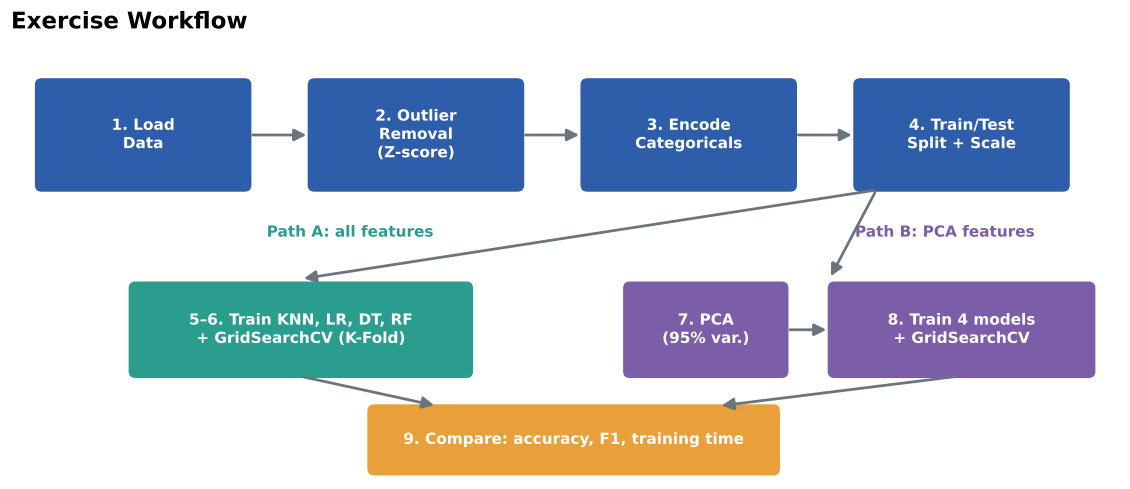

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [4]:
# Write your code here
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from scipy.stats import zscore
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from sklearn.decomposition import PCA

# Make plots look neat
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [41]:
# Write your code here
# Load the dataset (keep heart.csv in the same folder as this notebook)
df = pd.read_csv("heart.csv")
display(df.head())

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [42]:
# Write your code here
# Dataset dimensions, column names and data types
print("Shape:", df.shape)
print("\\nColumns:")
print(df.columns.tolist())
print("\\nData types:")
print(df.dtypes)

Shape: (918, 12)
\nColumns:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']
\nData types:
Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object


### 1.3 Check for missing values

In [43]:
# Write your code here
# Count missing values in each column
print(df.isnull().sum())
print("\\nTotal missing values:", df.isnull().sum().sum())

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
\nTotal missing values: 0


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

In [44]:
# Write your code here
# Optional: target class balance
print(df["HeartDisease"].value_counts())
print("\\nProportion:")
print(df["HeartDisease"].value_counts(normalize=True).round(3))

HeartDisease
1    508
0    410
Name: count, dtype: int64
\nProportion:
HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64


**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

> ✍️ **Your answer:**

The dataset contains 918 rows and 12 columns. The text-based columns are Sex, ChestPainType, RestingECG, ExerciseAngina and ST_Slope. There are no missing values in the dataset. However, RestingBP contains one zero value and Cholesterol contains 172 zero values, which may represent invalid or missing measurements.


---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.

![zscore](attachment:zscore.png)

**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

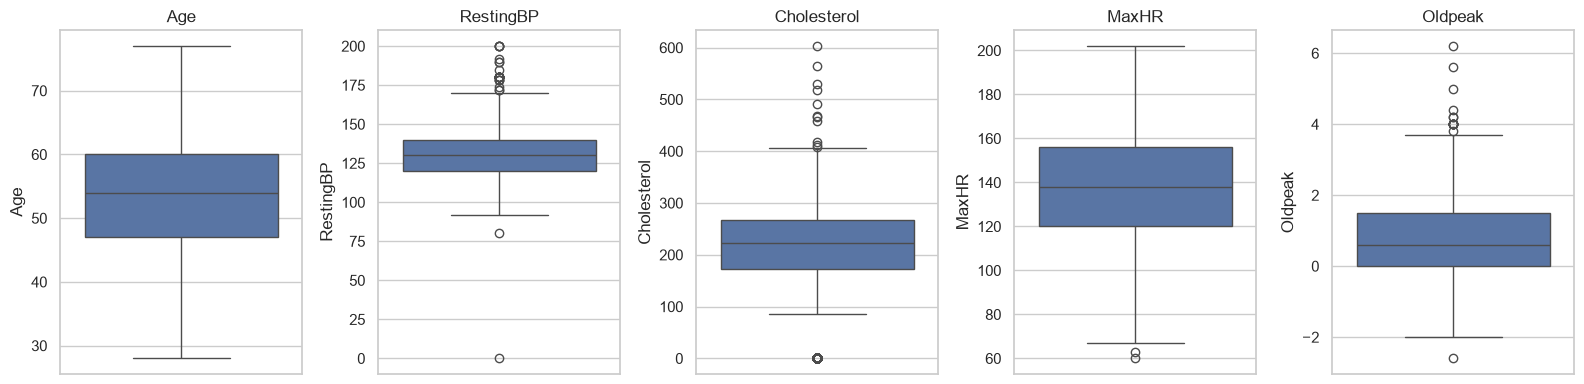

In [45]:
# Write your code here
# Boxplots of continuous numerical features before outlier removal
continuous_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
fig, axes = plt.subplots(1, len(continuous_cols), figsize=(16, 4))
for ax, col in zip(axes, continuous_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 2.2 Calculate Z-scores for the numerical features

In [46]:
# Write your code here
# Calculate Z-scores for the continuous numerical features
z_scores = df[continuous_cols].apply(lambda col: zscore(col, nan_policy="omit"))
display(z_scores.head())

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,-1.433140,0.410909,0.825070,1.382928,-0.832432
1,-0.478484,1.491752,-0.171961,0.754157,0.105664
2,-1.751359,-0.129513,0.770188,-1.525138,-0.832432
3,-0.584556,0.302825,0.139040,-1.132156,0.574711
4,0.051881,0.951331,-0.034755,-0.581981,-0.832432


### 2.3 Identify and count the outlier records

In [47]:
# Write your code here
# Identify records with at least one absolute Z-score greater than 3
outlier_mask = (z_scores.abs() > 3).any(axis=1)
print("Number of outlier records:", int(outlier_mask.sum()))
print("Outliers by feature:")
print((z_scores.abs() > 3).sum())

Number of outlier records: 19
Outliers by feature:
Age            0
RestingBP      8
Cholesterol    3
MaxHR          1
Oldpeak        7
dtype: int64


### 2.4 Remove the outliers and display the new shape

In [48]:
# Write your code here
# Remove outlier records and report dataset shape
df_before_outliers = df.copy()
df_clean = df.loc[~outlier_mask].copy()
print("Before removal:", df_before_outliers.shape)
print("After removal:", df_clean.shape)
print("Records removed:", len(df_before_outliers) - len(df_clean))

Before removal: (918, 12)
After removal: (899, 12)
Records removed: 19


**Q2.** How many records were removed? Which feature contributed the most outliers?

> ✍️ **Your answer:**
>
> _Double-click this cell and write your answer here._

Using the Z-score method with a threshold of ±3, a total of 19 records were identified as outliers and removed. RestingBP contributed the highest number of outlier values, with 8 records. Removing outliers helps reduce the influence of extreme values and improves data quality.

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.

![encoding](attachment:encoding.png)

| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [50]:
# Identify categorical columns and their unique values
categorical_cols = df_clean.select_dtypes(include="str").columns.tolist()

print("Categorical columns:", categorical_cols)

for col in categorical_cols:
    print(f"{col}: {df_clean[col].unique()}")

Categorical columns: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Sex: <StringArray>
['M', 'F']
Length: 2, dtype: str
ChestPainType: <StringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str
RestingECG: <StringArray>
['Normal', 'ST', 'LVH']
Length: 3, dtype: str
ExerciseAngina: <StringArray>
['N', 'Y']
Length: 2, dtype: str
ST_Slope: <StringArray>
['Up', 'Flat', 'Down']
Length: 3, dtype: str


### 3.2 Apply Label Encoding

In [51]:
# Write your code here
# Label-encode the binary categorical columns
df_encoded = df_clean.copy()
binary_cols = ["Sex", "ExerciseAngina"]
label_encoders = {}
for col in binary_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le
print("Label encoded columns:", binary_cols)
display(df_encoded[binary_cols].head())

Label encoded columns: ['Sex', 'ExerciseAngina']


,Sex,ExerciseAngina
0,1,0
1,0,0
2,1,0
3,0,1
4,1,0


### 3.3 Apply One-Hot Encoding

In [52]:
# Write your code here
# One-hot encode nominal categorical columns (drop_first avoids redundant dummy columns)
nominal_cols = ["ChestPainType", "RestingECG", "ST_Slope"]
df_encoded = pd.get_dummies(df_encoded, columns=nominal_cols, drop_first=True, dtype=int)
display(df_encoded.head())

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,1,0,1,0,0,1


### 3.4 Display the final encoded dataset

In [53]:
# Write your code here
# Final encoded dataset
print("Encoded dataset shape:", df_encoded.shape)
print("Columns:", df_encoded.columns.tolist())
display(df_encoded.head())

Encoded dataset shape: (899, 16)
Columns: ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'HeartDisease', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,1,0,1,0,0,1


**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

 Label Encoding was used for binary categorical features such as Sex and ExerciseAngina because they contain only two categories. One-Hot Encoding was used for ChestPainType, RestingECG and ST_Slope because they contain multiple nominal categories without any natural order.

The drop_first=True option was used to avoid redundant dummy variables. After encoding, the dataset contains 16 columns, including the target variable, and 15 input features.

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.

![leakage](attachment:leakage.png)

**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [54]:
# Write your code here
# Separate features (X) and target (y)
X = df_encoded.drop(columns=["HeartDisease"])
y = df_encoded["HeartDisease"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (899, 15)
y shape: (899,)


### 4.2 Split into training and testing sets

In [55]:
# Write your code here
# Split data into training and testing sets (stratified 80/20 split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (719, 15)
Testing set: (180, 15)


### 4.3 Apply feature scaling (fit on training data only)

In [56]:
# Write your code here
# Fit scaler ONLY on training data to prevent data leakage
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (719, 15)
Scaled testing shape: (180, 15)


**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

> ✍️ **Your answer:**

I chose StandardScaler because it transforms the features to have approximately zero mean and unit variance. It is useful for distance-based algorithms such as KNN and Logistic Regression.

The scaler was fitted only on the training data and then applied to the testing data. If the scaler is fitted on the entire dataset before splitting, information from the test data may leak into the training process. This causes data leakage and can lead to misleading evaluation results.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [57]:
# Write your code here
# Helper function: fit model, measure training time and calculate test metrics
def evaluate_model(model, Xtr, Xte, ytr, yte, model_name):
    start = time.time()
    model.fit(Xtr, ytr)
    train_seconds = time.time() - start
    predictions = model.predict(Xte)
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(yte, predictions),
        "Precision": precision_score(yte, predictions, zero_division=0),
        "Recall": recall_score(yte, predictions, zero_division=0),
        "F1-score": f1_score(yte, predictions, zero_division=0),
        "Training Time (s)": train_seconds
    }
    print(f"\\n{model_name}")
    print(classification_report(yte, predictions, zero_division=0))
    print("Confusion matrix:\\n", confusion_matrix(yte, predictions))
    return model, metrics

### 5.2 K-Nearest Neighbors

In [58]:
# Write your code here
# K-Nearest Neighbors (default parameters)
knn_model, knn_metrics = evaluate_model(
    KNeighborsClassifier(), X_train_scaled, X_test_scaled, y_train, y_test, "KNN"
)

\nKNN
              precision    recall  f1-score   support

           0       0.90      0.85      0.87        81
           1       0.88      0.92      0.90        99

    accuracy                           0.89       180
   macro avg       0.89      0.89      0.89       180
weighted avg       0.89      0.89      0.89       180

Confusion matrix:\n [[69 12]
 [ 8 91]]


### 5.3 Logistic Regression

In [59]:
# Write your code here
# Logistic Regression (default parameters)
lr_model, lr_metrics = evaluate_model(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    X_train_scaled, X_test_scaled, y_train, y_test, "Logistic Regression"
)

\nLogistic Regression
              precision    recall  f1-score   support

           0       0.87      0.84      0.86        81
           1       0.87      0.90      0.89        99

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180

Confusion matrix:\n [[68 13]
 [10 89]]


### 5.4 Decision Tree

In [60]:
# Write your code here
# Decision Tree (default parameters)
dt_model, dt_metrics = evaluate_model(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    X_train_scaled, X_test_scaled, y_train, y_test, "Decision Tree"
)

\nDecision Tree
              precision    recall  f1-score   support

           0       0.80      0.79      0.80        81
           1       0.83      0.84      0.83        99

    accuracy                           0.82       180
   macro avg       0.81      0.81      0.81       180
weighted avg       0.82      0.82      0.82       180

Confusion matrix:\n [[64 17]
 [16 83]]


### 5.5 Random Forest

In [61]:
# Write your code here
# Random Forest (default parameters)
rf_model, rf_metrics = evaluate_model(
    RandomForestClassifier(random_state=RANDOM_STATE),
    X_train_scaled, X_test_scaled, y_train, y_test, "Random Forest"
)

\nRandom Forest
              precision    recall  f1-score   support

           0       0.88      0.83      0.85        81
           1       0.87      0.91      0.89        99

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180

Confusion matrix:\n [[67 14]
 [ 9 90]]


### 5.6 Comparison table and bar chart of all four models

,Accuracy,Precision,Recall,F1-score,Training Time (s)
Model,,,,,
KNN,0.8889,0.8835,0.9192,0.9010,0.0072
Logistic Regression,0.8722,0.8725,0.8990,0.8856,0.0123
Decision Tree,0.8167,0.8300,0.8384,0.8342,0.0066
Random Forest,0.8722,0.8654,0.9091,0.8867,0.2647


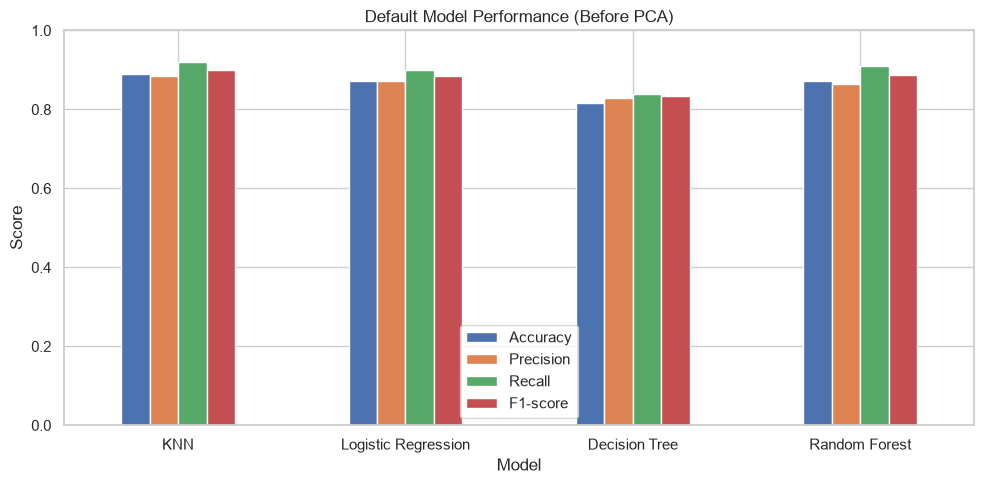

In [62]:
# Write your code here
# Compare default models in a table and bar chart
before_results = pd.DataFrame([knn_metrics, lr_metrics, dt_metrics, rf_metrics])
display(before_results.round(4).set_index("Model"))
before_results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0
)
plt.title("Default Model Performance (Before PCA)")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

> ✍️ **Your answer:**

The model with the highest test accuracy can be identified from the comparison table generated after training the four classifiers.

In medical diagnosis, recall should be prioritised because it measures how many actual heart disease patients are correctly identified. High recall helps reduce false negatives, which means fewer patients with heart disease are incorrectly classified as healthy. Therefore, recall is particularly important in medical applications.

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.

![kfold](attachment:kfold.png)

**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [2]:
# Write your code here
# Stratified 5-fold cross-validation and parameter grids
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = "f1"

param_grids = {
    "KNN": {
        "n_neighbors": [3, 5, 7, 9, 11],
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan"]
    },
    "Logistic Regression": {
        "C": [0.1, 1, 10],
        "solver": ["liblinear"],
        "penalty": ["l1", "l2"]
    },
    "Decision Tree": {
        "max_depth": [None, 5, 10, 20],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "criterion": ["gini", "entropy"]
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5],
        "max_features": ["sqrt", "log2"]
    }
}
print("Cross-validation strategy:", cv)
print("Scoring metric:", scoring)

NameError: name 'StratifiedKFold' is not defined

### 6.2 Tune KNN

In [3]:
# Tune KNN using training data only
knn_search = GridSearchCV(KNeighborsClassifier(), param_grids["KNN"], cv=cv, scoring=scoring, n_jobs=-1)
knn_search.fit(X_train_scaled, y_train)
knn_tuned, knn_tuned_metrics = evaluate_model(
    knn_search.best_estimator_, X_train_scaled, X_test_scaled, y_train, y_test, "Tuned KNN"
)
print("Best parameters:", knn_search.best_params_)
print("Best mean CV F1:", knn_search.best_score_)

NameError: name 'GridSearchCV' is not defined

### 6.3 Tune Logistic Regression

In [ ]:
# Write your code here
# Tune Logistic Regression
lr_search = GridSearchCV(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                         param_grids["Logistic Regression"], cv=cv, scoring=scoring, n_jobs=-1)
lr_search.fit(X_train_scaled, y_train)
lr_tuned, lr_tuned_metrics = evaluate_model(
    lr_search.best_estimator_, X_train_scaled, X_test_scaled, y_train, y_test, "Tuned Logistic Regression"
)
print("Best parameters:", lr_search.best_params_)
print("Best mean CV F1:", lr_search.best_score_)

### 6.4 Tune Decision Tree

In [65]:
# Write your code here
# Tune Decision Tree
dt_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                         param_grids["Decision Tree"], cv=cv, scoring=scoring, n_jobs=-1)
dt_search.fit(X_train_scaled, y_train)
dt_tuned, dt_tuned_metrics = evaluate_model(
    dt_search.best_estimator_, X_train_scaled, X_test_scaled, y_train, y_test, "Tuned Decision Tree"
)
print("Best parameters:", dt_search.best_params_)
print("Best mean CV F1:", dt_search.best_score_)

\nTuned Decision Tree
              precision    recall  f1-score   support

           0       0.77      0.86      0.81        81
           1       0.88      0.79      0.83        99

    accuracy                           0.82       180
   macro avg       0.82      0.83      0.82       180
weighted avg       0.83      0.82      0.82       180

Confusion matrix:\n [[70 11]
 [21 78]]
Best parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best mean CV F1: 0.8492476134117917


### 6.5 Tune Random Forest

In [66]:
# Write your code here
# Tune Random Forest
rf_search = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                         param_grids["Random Forest"], cv=cv, scoring=scoring, n_jobs=-1)
rf_search.fit(X_train_scaled, y_train)
rf_tuned, rf_tuned_metrics = evaluate_model(
    rf_search.best_estimator_, X_train_scaled, X_test_scaled, y_train, y_test, "Tuned Random Forest"
)
print("Best parameters:", rf_search.best_params_)
print("Best mean CV F1:", rf_search.best_score_)

\nTuned Random Forest
              precision    recall  f1-score   support

           0       0.89      0.80      0.84        81
           1       0.85      0.92      0.88        99

    accuracy                           0.87       180
   macro avg       0.87      0.86      0.86       180
weighted avg       0.87      0.87      0.87       180

Confusion matrix:\n [[65 16]
 [ 8 91]]
Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 100}
Best mean CV F1: 0.8896664281533658


### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

In [72]:
# Re-run hyperparameter tuning for all four models

knn_search = GridSearchCV(
    KNeighborsClassifier(),
    param_grids["KNN"],
    cv=cv,
    scoring="f1",
    n_jobs=-1
)
knn_search.fit(X_train_scaled, y_train)

lr_search = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    param_grids["Logistic Regression"],
    cv=cv,
    scoring="f1",
    n_jobs=-1
)
lr_search.fit(X_train_scaled, y_train)

dt_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grids["Decision Tree"],
    cv=cv,
    scoring="f1",
    n_jobs=-1
)
dt_search.fit(X_train_scaled, y_train)

rf_search = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_grids["Random Forest"],
    cv=cv,
    scoring="f1",
    n_jobs=-1
)
rf_search.fit(X_train_scaled, y_train)

print("All four models fitted successfully!")
print("KNN:", knn_search.best_score_)
print("Logistic Regression:", lr_search.best_score_)
print("Decision Tree:", dt_search.best_score_)
print("Random Forest:", rf_search.best_score_)

C:\Users\rdeet\dslab\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


All four models fitted successfully!
KNN: 0.8932133072665671
Logistic Regression: 0.8780912508480487
Decision Tree: 0.8492476134117917
Random Forest: 0.8896664281533658


In [73]:
# Write your code here
# Comparison of tuned models (test metrics, CV score and training time)
tuned_results = pd.DataFrame([
    {**knn_tuned_metrics, "Best CV F1": knn_search.best_score_},
    {**lr_tuned_metrics, "Best CV F1": lr_search.best_score_},
    {**dt_tuned_metrics, "Best CV F1": dt_search.best_score_},
    {**rf_tuned_metrics, "Best CV F1": rf_search.best_score_}
])
display(tuned_results.round(4).set_index("Model"))

,Accuracy,Precision,Recall,F1-score,Training Time (s),Best CV F1
Model,,,,,,
Tuned KNN,0.8944,0.8922,0.9192,0.9055,0.0098,0.8932
Tuned Logistic Regression,0.8778,0.8738,0.9091,0.8911,0.0060,0.8781
Tuned Decision Tree,0.8222,0.8764,0.7879,0.8298,0.0043,0.8492
Tuned Random Forest,0.8667,0.8505,0.9192,0.8835,0.2223,0.8897


**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

> ✍️ **Your answer:**

Hyperparameter tuning does not necessarily improve every model. It helps identify the best parameter combinations using cross-validation. Some models may show improved accuracy and F1-score, while others may show only small improvements or even a decrease in performance.

The model that shows the largest improvement in F1-score after tuning can be considered the most benefited model. This happens because suitable hyperparameters help the model learn patterns more effectively and improve its generalisation.

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.

![pca](attachment:pca.png)

**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

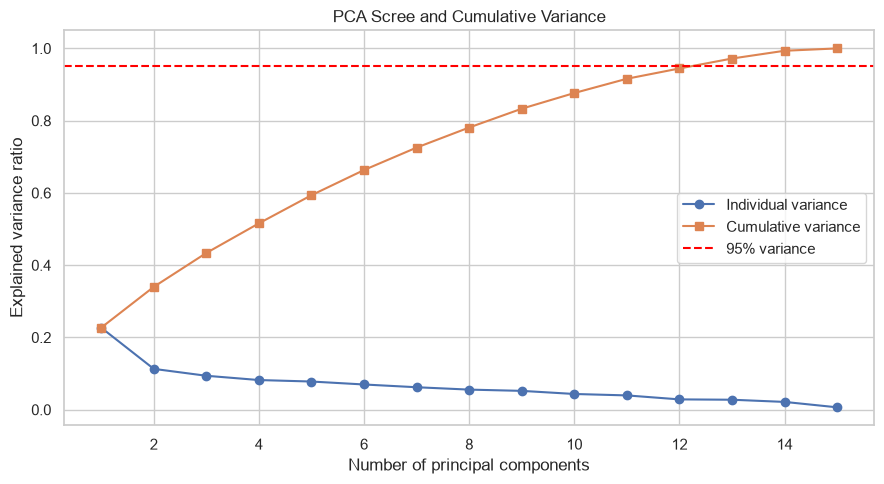

In [74]:
# Write your code here
# Fit PCA on scaled training data only, then inspect explained variance
pca_all = PCA()
pca_all.fit(X_train_scaled)
explained = pca_all.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(explained) + 1), explained, marker="o", label="Individual variance")
plt.plot(range(1, len(cumulative) + 1), cumulative, marker="s", label="Cumulative variance")
plt.axhline(0.95, color="red", linestyle="--", label="95% variance")
plt.xlabel("Number of principal components")
plt.ylabel("Explained variance ratio")
plt.title("PCA Scree and Cumulative Variance")
plt.legend()
plt.tight_layout()
plt.show()

### 7.2 Determine the number of components for 95% variance

In [75]:
# Write your code here
# Find the minimum number of components needed to retain at least 95% variance
n_components_95 = int(np.argmax(cumulative >= 0.95) + 1)
print("Components needed for 95% variance:", n_components_95)
print("Original feature count:", X_train_scaled.shape[1])
print("Feature reduction: {:.2f}%".format(
    100 * (1 - n_components_95 / X_train_scaled.shape[1])
))

Components needed for 95% variance: 13
Original feature count: 15
Feature reduction: 13.33%


### 7.3 Transform the training and testing sets

In [76]:
# Write your code here
# Transform train and test data using PCA fitted on training data only
pca = PCA(n_components=n_components_95)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print("PCA training shape:", X_train_pca.shape)
print("PCA testing shape:", X_test_pca.shape)

PCA training shape: (719, 13)
PCA testing shape: (180, 13)


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

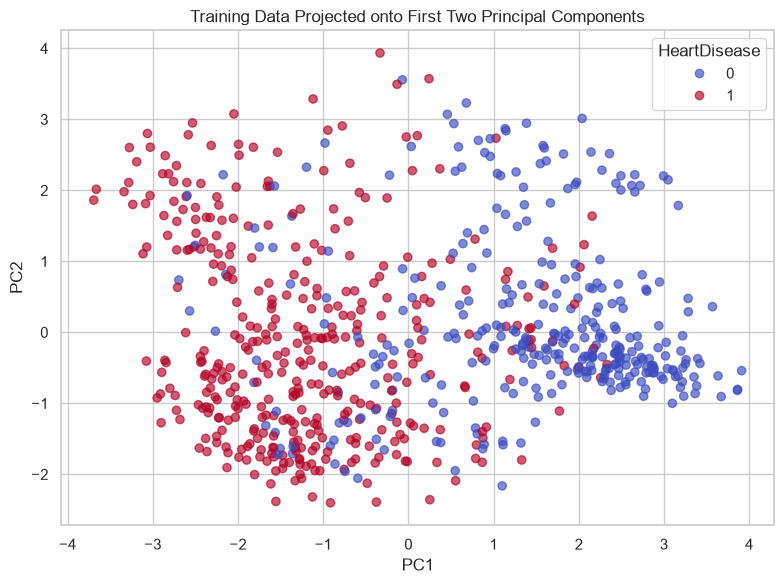

In [77]:
# Write your code here
# Optional: visualise first two principal components (if available)
if X_train_pca.shape[1] >= 2:
    pca_2d = PCA(n_components=2)
    train_2d = pca_2d.fit_transform(X_train_scaled)
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(train_2d[:, 0], train_2d[:, 1], c=y_train, alpha=0.65, cmap="coolwarm")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("Training Data Projected onto First Two Principal Components")
    plt.legend(*scatter.legend_elements(), title="HeartDisease")
    plt.tight_layout()
    plt.show()

**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

> ✍️ **Your answer:**

A total of 13 principal components are needed to retain at least 95% of the variance. The original dataset contains 15 input features, which are reduced to 13 components.

The dimensionality reduction percentage is approximately 13.33%. PCA reduces the number of features while retaining most of the important information.

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

In [78]:
# Write your code here
# Tune and evaluate KNN after PCA
knn_pca_search = GridSearchCV(KNeighborsClassifier(), param_grids["KNN"], cv=cv, scoring=scoring, n_jobs=-1)
start = time.time()
knn_pca_search.fit(X_train_pca, y_train)
knn_pca_seconds = time.time() - start
knn_pca_model = knn_pca_search.best_estimator_
knn_pca_pred = knn_pca_model.predict(X_test_pca)
knn_pca_metrics = {"Model": "KNN", "Accuracy": accuracy_score(y_test, knn_pca_pred),
                   "Precision": precision_score(y_test, knn_pca_pred, zero_division=0),
                   "Recall": recall_score(y_test, knn_pca_pred, zero_division=0),
                   "F1-score": f1_score(y_test, knn_pca_pred, zero_division=0),
                   "Training Time (s)": knn_pca_seconds}
print("Best parameters:", knn_pca_search.best_params_)
print("Best CV F1:", knn_pca_search.best_score_)
print("Confusion matrix:\\n", confusion_matrix(y_test, knn_pca_pred))
print(classification_report(y_test, knn_pca_pred, zero_division=0))

Best parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best CV F1: 0.8844401799633081
Confusion matrix:\n [[71 10]
 [ 6 93]]
              precision    recall  f1-score   support

           0       0.92      0.88      0.90        81
           1       0.90      0.94      0.92        99

    accuracy                           0.91       180
   macro avg       0.91      0.91      0.91       180
weighted avg       0.91      0.91      0.91       180



### 8.2 Logistic Regression after PCA

In [83]:
# Write your code here
# Tune and evaluate Logistic Regression after PCA
lr_pca_search = GridSearchCV(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                             param_grids["Logistic Regression"], cv=cv, scoring=scoring, n_jobs=-1)
start = time.time()
lr_pca_search.fit(X_train_pca, y_train)
lr_pca_seconds = time.time() - start
lr_pca_model = lr_pca_search.best_estimator_
lr_pca_pred = lr_pca_model.predict(X_test_pca)
lr_pca_metrics = {"Model": "Logistic Regression", "Accuracy": accuracy_score(y_test, lr_pca_pred),
                  "Precision": precision_score(y_test, lr_pca_pred, zero_division=0),
                  "Recall": recall_score(y_test, lr_pca_pred, zero_division=0),
                  "F1-score": f1_score(y_test, lr_pca_pred, zero_division=0),
                  "Training Time (s)": lr_pca_seconds}
print("Best parameters:", lr_pca_search.best_params_)
print("Best CV F1:", lr_pca_search.best_score_)
print("Confusion matrix:\\n", confusion_matrix(y_test, lr_pca_pred))
print(classification_report(y_test, lr_pca_pred, zero_division=0))

Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV F1: 0.8811501882019146
Confusion matrix:\n [[69 12]
 [10 89]]
              precision    recall  f1-score   support

           0       0.87      0.85      0.86        81
           1       0.88      0.90      0.89        99

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180



C:\Users\rdeet\dslab\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


### 8.3 Decision Tree after PCA

In [84]:
# Write your code here
# Tune and evaluate Decision Tree after PCA
dt_pca_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                             param_grids["Decision Tree"], cv=cv, scoring=scoring, n_jobs=-1)
start = time.time()
dt_pca_search.fit(X_train_pca, y_train)
dt_pca_seconds = time.time() - start
dt_pca_model = dt_pca_search.best_estimator_
dt_pca_pred = dt_pca_model.predict(X_test_pca)
dt_pca_metrics = {"Model": "Decision Tree", "Accuracy": accuracy_score(y_test, dt_pca_pred),
                  "Precision": precision_score(y_test, dt_pca_pred, zero_division=0),
                  "Recall": recall_score(y_test, dt_pca_pred, zero_division=0),
                  "F1-score": f1_score(y_test, dt_pca_pred, zero_division=0),
                  "Training Time (s)": dt_pca_seconds}
print("Best parameters:", dt_pca_search.best_params_)
print("Best CV F1:", dt_pca_search.best_score_)
print("Confusion matrix:\\n", confusion_matrix(y_test, dt_pca_pred))
print(classification_report(y_test, dt_pca_pred, zero_division=0))

Best parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best CV F1: 0.8507166367627716
Confusion matrix:\n [[66 15]
 [19 80]]
              precision    recall  f1-score   support

           0       0.78      0.81      0.80        81
           1       0.84      0.81      0.82        99

    accuracy                           0.81       180
   macro avg       0.81      0.81      0.81       180
weighted avg       0.81      0.81      0.81       180



### 8.4 Random Forest after PCA

In [85]:
# Write your code here
# Tune and evaluate Random Forest after PCA
rf_pca_search = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                             param_grids["Random Forest"], cv=cv, scoring=scoring, n_jobs=-1)
start = time.time()
rf_pca_search.fit(X_train_pca, y_train)
rf_pca_seconds = time.time() - start
rf_pca_model = rf_pca_search.best_estimator_
rf_pca_pred = rf_pca_model.predict(X_test_pca)
rf_pca_metrics = {"Model": "Random Forest", "Accuracy": accuracy_score(y_test, rf_pca_pred),
                  "Precision": precision_score(y_test, rf_pca_pred, zero_division=0),
                  "Recall": recall_score(y_test, rf_pca_pred, zero_division=0),
                  "F1-score": f1_score(y_test, rf_pca_pred, zero_division=0),
                  "Training Time (s)": rf_pca_seconds}
print("Best parameters:", rf_pca_search.best_params_)
print("Best CV F1:", rf_pca_search.best_score_)
print("Confusion matrix:\\n", confusion_matrix(y_test, rf_pca_pred))
print(classification_report(y_test, rf_pca_pred, zero_division=0))

Best parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 100}
Best CV F1: 0.8802237216906568
Confusion matrix:\n [[68 13]
 [ 8 91]]
              precision    recall  f1-score   support

           0       0.89      0.84      0.87        81
           1       0.88      0.92      0.90        99

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180



### 8.5 Comparison table of all four models after PCA

,Accuracy,Precision,Recall,F1-score,Training Time (s)
Model,,,,,
KNN,0.9111,0.9029,0.9394,0.9208,0.5828
Logistic Regression,0.8778,0.8812,0.8990,0.8900,0.1551
Decision Tree,0.8111,0.8421,0.8081,0.8247,1.0422
Random Forest,0.8833,0.8750,0.9192,0.8966,9.2070


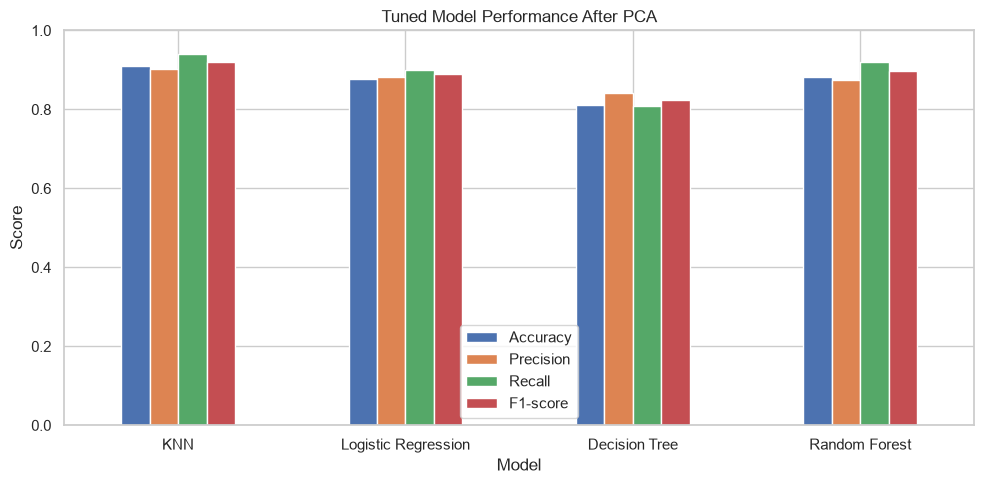

In [86]:
# Write your code here
# Comparison table for all four tuned models after PCA
after_results = pd.DataFrame([knn_pca_metrics, lr_pca_metrics, dt_pca_metrics, rf_pca_metrics])
display(after_results.round(4).set_index("Model"))
after_results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0
)
plt.title("Tuned Model Performance After PCA")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

> ✍️ **Your answer:**

The best-performing model after PCA can be identified by comparing the accuracy, precision, recall and F1-score of all four models.

PCA may change the performance of the models because it transforms the original features into new principal components. The best model after PCA may or may not be the same as the best model before PCA.

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

In [87]:
# Write your code here
# Consolidated comparison: tuned models before PCA vs tuned models after PCA
before_tuned = pd.DataFrame([
    {**knn_tuned_metrics, "Model": "KNN"},
    {**lr_tuned_metrics, "Model": "Logistic Regression"},
    {**dt_tuned_metrics, "Model": "Decision Tree"},
    {**rf_tuned_metrics, "Model": "Random Forest"}
]).set_index("Model")
after_tuned = after_results.set_index("Model")

comparison = pd.DataFrame(index=before_tuned.index)
comparison["Accuracy (Before PCA)"] = before_tuned["Accuracy"]
comparison["Accuracy (After PCA)"] = after_tuned["Accuracy"]
comparison["F1 (Before PCA)"] = before_tuned["F1-score"]
comparison["F1 (After PCA)"] = after_tuned["F1-score"]
comparison["Training Time Before (s)"] = before_tuned["Training Time (s)"]
comparison["Training Time After (s)"] = after_tuned["Training Time (s)"]
comparison["No. of Features"] = X_train_scaled.shape[1].astype(int) if hasattr(X_train_scaled.shape[1], "astype") else X_train_scaled.shape[1]
display(comparison.round(4))

,Accuracy (Before PCA),Accuracy (After PCA),F1 (Before PCA),F1 (After PCA),Training Time Before (s),Training Time After (s),No. of Features
Model,,,,,,,
KNN,0.8944,0.9111,0.9055,0.9208,0.0098,0.5828,15
Logistic Regression,0.8778,0.8778,0.8911,0.8900,0.0060,0.1551,15
Decision Tree,0.8222,0.8111,0.8298,0.8247,0.0043,1.0422,15
Random Forest,0.8667,0.8833,0.8835,0.8966,0.2223,9.2070,15


### 9.2 Visualise the before vs after PCA comparison

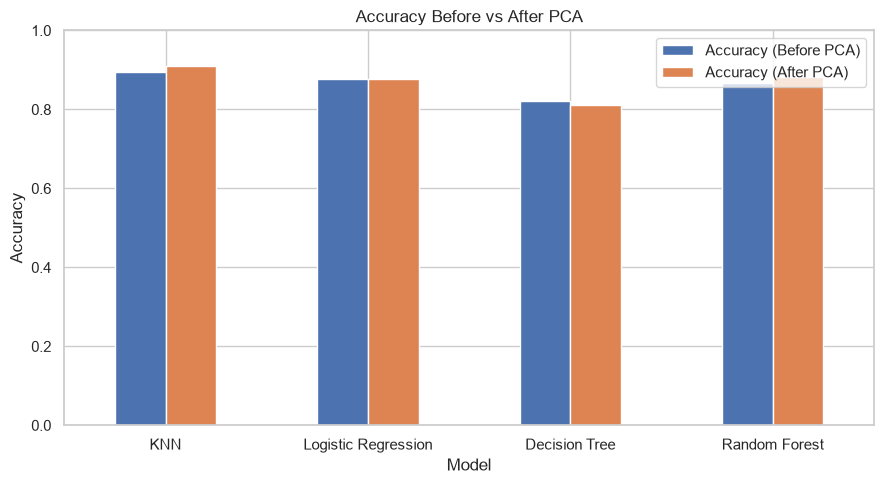

In [88]:
# Write your code here
# Grouped bar chart comparing accuracy before and after PCA
comparison[["Accuracy (Before PCA)", "Accuracy (After PCA)"]].plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1), rot=0
)
plt.title("Accuracy Before vs After PCA")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()

### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

> ✍️ **Your answer:**

The performance of the models may change after applying PCA. Some models may improve because PCA reduces redundant information and removes correlations between features. Other models may experience a decrease in performance because PCA can remove useful information required for classification.

The models with higher accuracy and F1-score after PCA are considered improved, while those with lower scores are considered declined.

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

> ✍️ **Your answer:**

PCA reduces the number of input features by transforming them into a smaller set of principal components. This can reduce computational complexity, memory usage and training time.

In this assignment, the number of features was reduced from 15 to 13. However, the improvement in computational efficiency may be small because the original dataset contains a relatively small number of features.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

> ✍️ **Your answer:**

Dimensionality reduction does not always improve classification performance. In this dataset, PCA may improve some models and reduce the performance of others.

This happens because PCA preserves directions with maximum variance, not necessarily the features that are most useful for predicting heart disease. Distance-based models such as KNN may benefit from reduced dimensionality, while tree-based models may lose some useful information.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

> ✍️ **Your answer:**

There is a trade-off between predictive accuracy, computational cost and dimensionality reduction.

PCA reduces the number of features, which can decrease computational cost and improve processing efficiency. However, reducing too many features may cause information loss and decrease predictive accuracy.

PCA is useful when working with large datasets containing many correlated features, such as medical data, image processing, face recognition and gene expression analysis. It helps simplify data while retaining most of its important information.

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.